# How Machines See: Giới thiệu về Thị giác Máy tính (Computer Vision)

## Chương trình (Agenda)
* Tổng quan
* Kiến thức nền tảng
* CNN
* Vision Transformer
* Kết luận



Notebook Colab này được xây dựng dựa trên [pytorch introduction](https://colab.research.google.com/drive/1iZ4P2mirQ4SrpH_6GchTMV-NlzyDzFC3) và [transformer introduction](https://colab.research.google.com/drive/1BYchvKEsS79ebHqOQqinJBZmDo_F_4Tj)




## Tổng quan


>Thị giác máy tính (Computer vision) là việc dạy cho máy móc cách diễn giải và hiểu hình ảnh, video theo cách con người làm. Giống như mắt chúng ta thu nhận ánh sáng và não bộ xử lý nó, các hệ thống thị giác máy tính sử dụng camera và thuật toán để "nhìn thấy" và "hiểu" thế giới.



### Ứng dụng trong thực tế
Nó vận hành những thứ chúng ta tương tác hàng ngày:

Nhận diện vật thể (object recognition)
<p align="center">
<img src="https://cdn-images-1.medium.com/v2/resize:fit:1000/1*QyW8eCwpRzw5rDpW75-YfA.gif" width="500" alt="transformer">
</p>

Mở khóa bằng khuôn mặt (Face unlock) trên điện thoại
<p align="center">
<img src="https://imageio.forbes.com/specials-images/imageserve/61a50e8ee60b65755906c32e/Apple-Face-ID-used-to-unlock-iPhone/960x0.jpg?format=jpg&width=960" width="500" alt="transformer">
</p>

Xe tự lái nhận diện đường và người đi bộ
<p align="center">
<img src="https://raw.githubusercontent.com/tejaslodaya/car-detection-yolo/master/nb_images/prediction_output.jpg" width="500" alt="transformer">
</p>

Hình ảnh y tế phát hiện khối u
<p align="center">
<img src="https://pub.mdpi-res.com/applsci/applsci-13-03808/article_deploy/html/images/applsci-13-03808-g003.png?1678964505" width="500" alt="transformer">
</p>

Thanh toán bán lẻ không cần thu ngân (Retail checkout without a cashier)

Bộ lọc mạng xã hội thêm mặt nạ vào ảnh selfie
<p align="center">
<img src="https://i.insider.com/56e042a2dd089576298b45ef?width=800&format=jpeg&auto=webp" width="500" alt="transformer">
</p>


## Mạng nơ-ron (Neural Network)

#### mô hình
**Chúng ta sẽ bắt đầu từ việc giới thiệu hồi quy tuyến tính (linear regression). Bài toán hồi quy xuất hiện bất cứ khi nào chúng ta muốn dự đoán một giá trị số.** Các ví dụ phổ biến bao gồm dự đoán giá (nhà, cổ phiếu, v.v.), dự đoán thời gian nằm viện (của bệnh nhân), dự báo nhu cầu (cho doanh số bán lẻ).

**Giả định về tính tuyến tính nghĩa là giá trị kỳ vọng của mục tiêu (giá) có thể được biểu diễn dưới dạng tổng có trọng số của các đặc trưng (diện tích và tuổi nhà):**

$price = w_{area}\cdot area+w_{age}\cdot age +b$

trong đó $w_{area}$ và $w_{age}$ được gọi là các trọng số (weight) và $b$ được gọi là độ lệch (bias). $(area, age)$ là một điểm dữ liệu trong tập dữ liệu.





<p align="center">
<img src='https://miro.medium.com/v2/resize:fit:1400/format:webp/1*L9xLcwKhuZ2cuS8fF0ZjwA.png' width="600px"/>
</p>

[nguồn ảnh](https://towardsdatascience.com/power-of-a-single-neuron-perceptron-c418ba445095)

<p align="center">
<img src='https://miro.medium.com/v2/resize:fit:1400/1*I-MxKoiWxJXLfExpvbT1eQ.png
' width="600px"/>
</p>

[nguồn ảnh](https://medium.com/@dhaval.sony.504/everything-in-short-about-simple-linear-regression-633fc9f8dd65)





### Perceptron đa lớp (Multilayer Perceptron - MLP)

#### lớp ẩn (hidden layer)
Mối quan hệ giữa đặc trưng và đầu ra không phải lúc nào cũng tuyến tính. Khi đó, hồi quy tuyến tính không còn phù hợp. "Chúng ta có thể khắc phục hạn chế của các mô hình tuyến tính bằng cách thêm một hoặc nhiều lớp ẩn. Cách đơn giản nhất là xếp chồng nhiều lớp kết nối đầy đủ (fully connected) lên nhau. Mỗi lớp truyền đầu ra vào lớp phía trên nó, cho đến khi ta tạo ra đầu ra cuối cùng. Ta có thể coi các lớp đầu tiên là phần biểu diễn (representation) và lớp cuối cùng là bộ dự đoán tuyến tính. Kiến trúc này thường được gọi là perceptron đa lớp, hay viết tắt là MLP." \[[dive into deep learning](https://d2l.ai/chapter_multilayer-perceptrons/mlp.html)\]

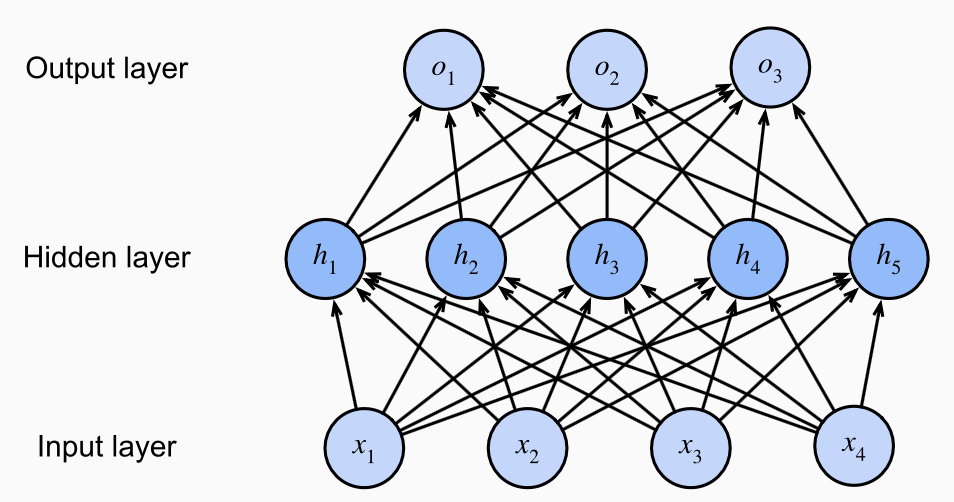


MLP này có bốn đầu vào, ba đầu ra, và lớp ẩn của nó chứa năm đơn vị ẩn (hidden unit). Lưu ý rằng cả hai lớp đều được kết nối đầy đủ. Mỗi đầu vào ảnh hưởng đến mọi nơ-ron trong lớp ẩn, và mỗi nơ-ron này lại ảnh hưởng đến mọi nơ-ron trong lớp đầu ra.
Bây giờ, ta có thể biểu diễn mạng này dưới dạng vector-ma trận:

$H = XW^{(1)} +b^{(1)}$

$O = HW^{(2)} +b^{(2)}$

$⇒ O = (XW^{(1)} +b^{(1)})W^{(2)} +b^{(2)}$

$X\in \mathbb{R}^{n \times 4},H\in \mathbb{R}^{n \times 5}, O\in \mathbb{R}^{n \times 3},$

$ W^{(1)}\in \mathbb{R}^{4 \times 5}, b^{(1)}\in \mathbb{R}^{1 \times 5}$

$ W^{(2)}\in \mathbb{R}^{5 \times 3}, b^{(2)}\in \mathbb{R}^{1 \times 3}$

ta có thể thấy rằng mối quan hệ giữa $X$ và $O$ vẫn là tuyến tính.

#### hàm kích hoạt (activation)

 chúng ta cần thêm một thành phần quan trọng nữa: một hàm kích hoạt phi tuyến (nonlinear activation function) được áp dụng cho từng đơn vị ẩn. Ví dụ, một lựa chọn phổ biến là hàm kích hoạt ReLU (rectified linear unit) $\sigma(x) = max(0,x)$ hoạt động theo từng phần tử trên các đối số của nó.


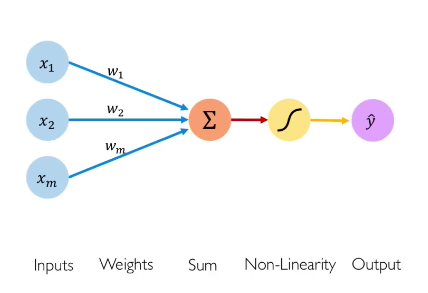

[nguồn ảnh](https://medium.com/analytics-vidhya/neural-network-part1-inside-a-single-neuron-fee5e44f1e)

một vài minh họa về các hàm mất mát (loss function)

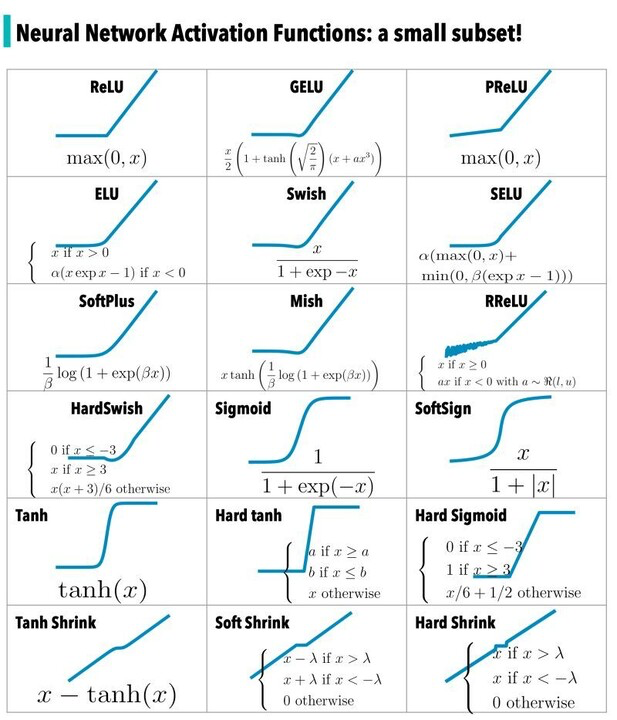

[nguồn ảnh](https://www.linkedin.com/pulse/activation-functions-heba-al-haddad/)

$H = \sigma(XW^{(1)} +b^{(1)})$

$O = HW^{(2)} +b^{(2)}$

Để xây dựng các MLP tổng quát hơn, ta có thể tiếp tục xếp chồng các lớp ẩn như vậy lên nhau, tạo ra các mô hình ngày càng biểu đạt (expressive) hơn.

<p align="center">
<img src="https://miro.medium.com/v2/resize:fit:1000/format:webp/1*63sGPbvLLpvlD16hG1bvmA.gif" width="600" alt="transformer">


### tóm tắt
Chúng ta vừa học về Perceptron đa lớp (MLPs). Trong một MLP, mỗi nơ-ron ở một lớp được kết nối với mọi nơ-ron ở lớp tiếp theo, tạo thành một cấu trúc kết nối đầy đủ (fully connected). Thiết kế này hoạt động tốt cho nhiều tác vụ, nhưng nó cũng có một số hạn chế, đặc biệt khi xử lý dữ liệu như hình ảnh hoặc video.

## CNN
Mạng nơ-ron xử lý hình ảnh như thế nào? Trong máy tính, hình ảnh được lưu trữ dưới dạng các pixel.

<p align="center">
<img src="https://miro.medium.com/v2/resize:fit:1264/format:webp/1*KQ-PbDHziPSh7R6zdGgVTQ.png" width="500" alt="transformer">

Một cách tiếp cận đơn giản là biến đổi ma trận 2D thành một vector 1D rồi sử dụng một perceptron đa lớp (MLP) để đưa ra dự đoán.
<p align="center">
<img src="https://raw.githubusercontent.com/AviatorMoser/keras-mnist-tutorial/refs/heads/master/flatten.png" width="500" alt="transformer">

<p align="center">
<img src="https://miro.medium.com/v2/resize:fit:1000/format:webp/1*63sGPbvLLpvlD16hG1bvmA.gif" width="500" alt="transformer">

Cách này hoạt động tốt với ảnh nhỏ (ví dụ 56x56 pixel). Tuy nhiên, khi xử lý ảnh có độ phân giải cao, chẳng hạn ảnh RGB 3x1920x1080, kích thước đầu vào trở nên rất lớn—khoảng 6 triệu tham số—khiến việc xử lý hiệu quả trở nên khó khăn.

<p align="center">
<img src="https://miro.medium.com/v2/resize:fit:1400/format:webp/1*vkQ0hXDaQv57sALXAJquxA.jpeg" width="700" alt="transformer">


Đây chính là lúc Mạng nơ-ron tích chập (Convolutional Neural Networks - CNN) phát huy tác dụng.

Thay vì làm phẳng ảnh thành một vector 1D, CNN tận dụng cấu trúc không gian của ảnh. Chúng sử dụng các lớp tích chập (convolutional layer) để phát hiện các mẫu cục bộ (local pattern), như cạnh, góc, và kết cấu (texture), bằng cách áp dụng các bộ lọc (filter) lên các vùng nhỏ của ảnh. Các đặc trưng đã học này sau đó được truyền qua các lớp sâu hơn để nắm bắt các mẫu ngày càng phức tạp, giảm bớt nhu cầu về một số lượng lớn tham số đầu vào.

CNN hiệu quả hơn nhiều khi xử lý ảnh có độ phân giải cao vì chúng tập trung vào các mẫu cục bộ và sử dụng chia sẻ trọng số (weight sharing), giúp giảm số lượng tham số cần thiết để xử lý.

Như được minh họa trong ảnh, một CNN bao gồm nhiều thành phần chính. Đầu tiên, các lớp tích chập áp dụng các bộ lọc lên ảnh đầu vào, theo sau là các hàm kích hoạt phi tuyến (ví dụ ReLU). Điều này cho phép mạng học các đặc trưng quan trọng của ảnh. Sau đó, các lớp gộp (pooling layer) giảm kích thước không gian trong khi vẫn giữ lại các đặc trưng thiết yếu, giúp mạng hiệu quả hơn. Sau khi trích xuất đặc trưng, một Perceptron đa lớp (MLP) được sử dụng để đưa ra dự đoán dựa trên các đặc trưng được trích xuất bởi các lớp CNN.

### lớp tích chập (convolutional layer)

Các lớp tích chập là xương sống của CNN, vì chúng chứa các kernel (trọng số) đã học được để trích xuất các đặc trưng phân biệt ảnh phục vụ cho việc phân loại.
Mục đích chính của phép tích chập (convolution) là trích xuất các đặc điểm từ đầu vào, chẳng hạn như cạnh, màu sắc, và góc. Khi ta đi sâu hơn vào mạng, hệ thống bắt đầu nhận diện được các đặc điểm ngày càng phức tạp hơn, như hình dạng, chữ số, và các vùng khác nhau trên khuôn mặt.
Phần tích chập có thể được minh họa như sau:

<p align="center">
<img src="https://miro.medium.com/v2/resize:fit:1400/format:webp/1*O06nY1U7zoP4vE5AZEnxKA.gif" width="700" alt="transformer">

Dưới đây là giải thích về quá trình này:

* Ảnh đầu vào (bên trái): Ảnh được biểu diễn dưới dạng một ma trận giá trị pixel, với một vùng cụ thể được tô màu xanh. Trong trường hợp này, đó là một vùng 5x5 bên trong một ảnh lớn hơn.
* Kernel (ở giữa): Kernel (hay bộ lọc/filter) là một ma trận nhỏ hơn, thường là ma trận 3x3, chứa các trọng số có thể học được (learnable weight). Trong trường hợp này, kernel được hiển thị với các giá trị như 0, -1, 0, -1, 5, -1, v.v.
Quá trình tích chập:
* Kernel được đặt lên trên ảnh, bắt đầu từ góc trên bên trái, và các giá trị pixel nằm dưới kernel được nhân với các giá trị kernel tương ứng.
Các tích số này sau đó được cộng lại để tạo ra một giá trị duy nhất. Ví dụ, vùng đầu tiên của ảnh được tô màu xanh và kernel tạo ra giá trị 114 sau phép tích chập (được hiển thị màu xanh lá).
* Trượt kernel: Sau khi tính toán đầu ra cho vùng đầu tiên của ảnh, kernel trượt sang phải một bước và lặp lại quá trình cho vùng tiếp theo của ảnh.
Kernel tiếp tục trượt qua toàn bộ ảnh, thực hiện phép toán này cho từng vùng, tạo ra một ma trận các giá trị đầu ra.
* Đầu ra (bên phải): Kết quả của quá trình tích chập là một ma trận mới. Đầu ra này sau đó có thể được truyền qua các lớp khác của mạng nơ-ron, chẳng hạn như lớp gộp (pooling) hoặc lớp kết nối đầy đủ (fully connected).


* Bạn có thể đã để ý các số 0 xung quanh ảnh; đây là phần đệm (padding). Trong tích chập 2D, padding thêm các pixel bổ sung (thường là số 0) xung quanh ảnh đầu vào. Nó cho phép kernel xử lý các pixel ở biên và giúp giữ nguyên kích thước của bản đồ đặc trưng (feature map) đầu ra. Nếu không có padding, đầu ra sẽ nhỏ hơn đầu vào. Trong hình minh họa, padding cho phép kernel trượt qua toàn bộ ảnh, kể cả các cạnh, đảm bảo mọi vùng đều được đưa vào quá trình trích xuất đặc trưng.

Trong hình minh họa này, bộ lọc trượt mỗi lần một pixel; đây được gọi là stride 1. Stride trong tích chập 2D là kích thước bước mà kernel di chuyển khi trượt qua ảnh đầu vào. Stride bằng 1 nghĩa là kernel di chuyển một pixel mỗi lần, trong khi stride bằng 2 nghĩa là nó di chuyển hai pixel mỗi lần. Tăng stride sẽ làm giảm kích thước đầu ra, vì kernel bao phủ ít vị trí hơn.

[thêm minh họa về stride và padding](https://hannibunny.github.io/mlbook/neuralnetworks/convolutionDemos.html)

### gộp (pooling)
Pooling là một phép toán giảm mẫu (downsampling) trong CNN nhằm giảm kích thước không gian của bản đồ đặc trưng (feature map) trong khi vẫn giữ lại các thông tin quan trọng. Nó nâng cao hiệu quả tính toán và giúp ngăn ngừa overfitting. Hai loại phổ biến là:

Max Pooling: Chọn giá trị lớn nhất trong một vùng.
Average Pooling: Tính giá trị trung bình của vùng đó.

<p align="center">
<img src="https://miro.medium.com/v2/resize:fit:1400/format:webp/1*vOxthD0FpBR6fJcpPxq6Hg.gif" width="700" alt="transformer">

Đây là minh họa về max pooling

Bản đồ đặc trưng đầu vào là một ma trận 4x4, và một cửa sổ pooling 2x2 được sử dụng.
Cửa sổ pooling trượt qua bản đồ đặc trưng, bắt đầu từ góc trên bên trái. Với mỗi vùng 2x2, giá trị lớn nhất được chọn.
Trong vùng 2x2 đầu tiên (trên-trái: 1, 1, 5, 6), giá trị lớn nhất là 6.
Trong vùng tiếp theo (trên-phải: 2, 4, 7, 8), giá trị lớn nhất là 8.
Quá trình này tiếp tục cho các vùng còn lại.

Kết quả của phép max pooling này là một phiên bản đã giảm mẫu của bản đồ đặc trưng ban đầu, nắm bắt được các đặc trưng nổi bật nhất trong mỗi vùng.

### tóm tắt

Cho đến nay, chúng ta đã tìm hiểu về Mạng nơ-ron tích chập (CNN), được thiết kế để xử lý dữ liệu ảnh một cách hiệu quả bằng cách tận dụng phép tích chập để phát hiện các mẫu cục bộ, như cạnh, kết cấu, và hình dạng, đồng thời giảm số lượng tham số. CNN rất phù hợp cho các tác vụ như phân loại ảnh, phát hiện vật thể, và phân đoạn (segmentation), nơi các cấu trúc phân cấp không gian (spatial hierarchy) đóng vai trò then chốt trong việc hiểu dữ liệu.

## MLP so với CNN
[nguồn gốc ](https://colab.research.google.com/github/AviatorMoser/keras-mnist-tutorial/blob/master/MNIST%20in%20Keras.ipynb#scrollTo=wG0hpKMXkh-3)

Để giúp bạn hiểu các nguyên lý cơ bản của deep learning, demo này sẽ đi qua các bước cơ bản để xây dựng hai mô hình đơn giản (toy model) cho việc phân loại chữ số viết tay với độ chính xác vượt 95%. Mô hình đầu tiên là một mạng nơ-ron kết nối đầy đủ (fully-connected) cơ bản, và mô hình thứ hai là một mạng sâu hơn giới thiệu các khái niệm tích chập (convolution) và gộp (pooling).

Dữ liệu được sử dụng là bộ dữ liệu MNIST, chứa 60.000 ảnh huấn luyện và 10.000 ảnh kiểm thử. Chúng ta sẽ sử dụng Keras Python API với TensorFlow làm backend.

<img src="https://github.com/AviatorMoser/keras-mnist-tutorial/blob/master/mnist.png?raw=1" >

### MLP

In [3]:
pip install tensorflow

  Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl.metadata (4.5 kB)
Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl (350.8 MB)
   ---------------------------------------- 0.0/456.5 kB ? eta -:--:--
    --------------------------------------- 10.2/456.5 kB ? eta -:--:--
   --- ----------------------------------- 41.0/456.5 kB 393.8 kB/s eta 0:00:02
   ------- ------------------------------- 92.2/456.5 kB 655.4 kB/s eta 0:00:01
   ---------- --------------------------- 122.9/456.5 kB 722.1 kB/s eta 0:00:01
   -------------- ----------------------- 174.1/456.5 kB 751.6 kB/s eta 0:00:01
   ----------------- -------------------- 204.8/456.5 kB 778.2 kB/s eta 0:00:01
   ---------------------- --------------- 266.2/456.5 kB 820.5 kB/s eta 0:00:01
   -------------------------- ----------- 317.4/456.5 kB 895.6 kB/s eta 0:00:01
   ------------------------------ ------- 368.6/456.5 kB 919.0 kB/s eta 0:00:01
   ----------------------------------- -- 430.1/456.5 kB 960.7 kB/s eta 

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np                   # thư viện toán học nâng cao
import matplotlib.pyplot as plt      # các hàm vẽ đồ thị kiểu MATLAB
import random                        # dùng để sinh số ngẫu nhiên

from keras.datasets import mnist     # bộ dữ liệu MNIST có sẵn trong Keras
from keras.models import Sequential  # Loại model sẽ được sử dụng

from keras.layers import Dense, Dropout, Activation # Các loại layer sẽ dùng trong model
from keras.utils import to_categorical                      # Các công cụ liên quan đến NumPy

# TẢI DỮ LIỆU
# Dữ liệu MNIST được chia thành 60.000 ảnh huấn luyện 28 x 28 pixel và 10.000 ảnh kiểm thử 28 x 28 pixel
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("X_train shape", X_train.shape)
print("y_train shape", y_train.shape)
print("X_test shape", X_test.shape)
print("y_test shape", y_test.shape)
X_train = X_train.reshape(60000, 784) # biến đổi 60.000 ma trận 28 x 28 thành 60.000 vector độ dài 784.
X_test = X_test.reshape(10000, 784)   # biến đổi 10.000 ma trận 28 x 28 thành 10.000 vector độ dài 784.

X_train = X_train.astype('float32')   # đổi số nguyên thành số thực dấu phẩy động 32-bit
X_test = X_test.astype('float32')

X_train /= 255                        # chuẩn hóa từng giá trị pixel cho toàn bộ vector của mỗi đầu vào
X_test /= 255

print("Training matrix shape", X_train.shape)
print("Testing matrix shape", X_test.shape)
nb_classes = 10 # số lượng chữ số khác nhau

Y_train = to_categorical(y_train, nb_classes)
Y_test = to_categorical(y_test, nb_classes)
# Model Sequential là một chồng (stack) tuyến tính các layer và rất phổ biến.

# ĐỊNH NGHĨA MODEL
model = Sequential()
# Lớp ẩn đầu tiên là một tập hợp 512 node (nơ-ron nhân tạo).
# Mỗi node sẽ nhận một phần tử từ mỗi vector đầu vào và áp dụng trọng số cùng độ lệch (bias) lên nó.

model.add(Dense(512, input_shape=(784,))) #(784,) không phải lỗi gõ -- nó biểu diễn một vector độ dài 784!
# "activation" là một hàm phi tuyến được áp dụng lên đầu ra của lớp phía trên.
# Nó kiểm tra giá trị mới của node, và quyết định xem nơ-ron nhân tạo đó có "kích hoạt" (fire) hay không.
# Hàm Rectified Linear Unit (ReLU) biến tất cả các đầu vào âm cho các node ở lớp tiếp theo thành 0.
# Những đầu vào đó khi đó được coi là không kích hoạt.
# Các giá trị dương của một node được giữ nguyên.

model.add(Activation('relu'))
# Dropout đặt một số đầu ra ngẫu nhiên về 0 (tức là vô hiệu hóa kích hoạt của chúng)
# Dropout giúp bảo vệ model khỏi việc ghi nhớ hay "overfitting" dữ liệu huấn luyện.
model.add(Dropout(0.2))
# Lớp ẩn thứ hai trông giống hệt lớp đầu tiên.
# Tuy nhiên, thay vì mỗi trong 512 node nhận 784 đầu vào từ dữ liệu ảnh gốc,
# chúng nhận 512 đầu vào từ đầu ra của lớp 512-node đầu tiên.

model.add(Dense(512))
model.add(Activation('relu'))
model.add(Dropout(0.2))
# Lớp cuối cùng gồm 10 nơ-ron được kết nối đầy đủ với lớp 512-node phía trước.
# Lớp cuối cùng của một FCN nên bằng với số lớp mong muốn (10 trong trường hợp này).
model.add(Dense(10))
# Hàm kích hoạt "softmax" biểu diễn một phân phối xác suất trên K kết quả có thể xảy ra khác nhau.
# Các giá trị của nó đều không âm và có tổng bằng 1.

model.add(Activation('softmax'))
# Tóm tắt model đã xây dựng

model.summary()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 11s 1us/step
X_train shape (60000, 28, 28)
y_train shape (60000,)
X_test shape (10000, 28, 28)
y_test shape (10000,)
Training matrix shape (60000, 784)
Testing matrix shape (10000, 784)


c:\Users\AD\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         5,130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 669,706 (2.55 MB)

 Trainable params: 669,706 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# HUẤN LUYỆN MODEL
# Hãy dùng optimizer Adam để học
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train, Y_train,
          batch_size=128, epochs=5,
          verbose=1)

# ĐÁNH GIÁ HIỆU NĂNG
score = model.evaluate(X_test, Y_test)
print('Test score:', score[0])
print('Test accuracy:', score[1])

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9268 - loss: 0.2464
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9689 - loss: 0.1017
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9773 - loss: 0.0711
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9818 - loss: 0.0562
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9849 - loss: 0.0478
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9791 - loss: 0.0672
Test score: 0.06724317371845245
Test accuracy: 0.9790999889373779


### CNN

In [6]:
# import thêm một số công cụ bổ sung

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.layers import Conv2D, MaxPooling2D, ZeroPadding2D, GlobalAveragePooling2D, Flatten
from keras.layers import BatchNormalization

# Tải lại dữ liệu MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# Một lần nữa, thực hiện một số định dạng lại
# Ngoại trừ việc ta không làm phẳng mỗi ảnh thành vector độ dài 784 vì ta muốn thực hiện tích chập trước

X_train = X_train.reshape(60000, 28, 28, 1) #thêm một chiều bổ sung để biểu diễn kênh đơn (single-channel)
X_test = X_test.reshape(10000, 28, 28, 1)

X_train = X_train.astype('float32')         # đổi số nguyên thành số thực dấu phẩy động 32-bit
X_test = X_test.astype('float32')

X_train /= 255                              # chuẩn hóa từng giá trị pixel cho toàn bộ vector của mỗi đầu vào
X_test /= 255

print("Training matrix shape", X_train.shape)
print("Testing matrix shape", X_test.shape)
# định dạng one-hot cho các lớp

nb_classes = 10 # số lượng chữ số khác nhau

Y_train = to_categorical(y_train, nb_classes)
Y_test = to_categorical(y_test, nb_classes)

# ĐỊNH NGHĨA MODEL
model = Sequential()                                 # Xếp chồng tuyến tính các layer

# Lớp tích chập 1
model.add(Conv2D(32, (3, 3), input_shape=(28,28,1))) # 32 kernel 3x3 khác nhau -- nên có 32 feature map
model.add(BatchNormalization(axis=-1))               # chuẩn hóa mỗi feature map trước khi kích hoạt
convLayer01 = Activation('relu')                     # kích hoạt
model.add(convLayer01)

# Lớp tích chập 2
model.add(Conv2D(32, (3, 3)))                        # 32 kernel 3x3 khác nhau -- nên có 32 feature map
model.add(BatchNormalization(axis=-1))               # chuẩn hóa mỗi feature map trước khi kích hoạt
model.add(Activation('relu'))                        # kích hoạt
convLayer02 = MaxPooling2D(pool_size=(2,2))          # Gộp (pool) các giá trị lớn nhất qua kernel 2x2
model.add(convLayer02)

# Lớp tích chập 3
model.add(Conv2D(64,(3, 3)))                         # 64 kernel 3x3 khác nhau -- nên có 64 feature map
model.add(BatchNormalization(axis=-1))               # chuẩn hóa mỗi feature map trước khi kích hoạt
convLayer03 = Activation('relu')                     # kích hoạt
model.add(convLayer03)

# Lớp tích chập 4
model.add(Conv2D(64, (3, 3)))                        # 64 kernel 3x3 khác nhau -- nên có 64 feature map
model.add(BatchNormalization(axis=-1))               # chuẩn hóa mỗi feature map trước khi kích hoạt
model.add(Activation('relu'))                        # kích hoạt
convLayer04 = MaxPooling2D(pool_size=(2,2))          # Gộp (pool) các giá trị lớn nhất qua kernel 2x2
model.add(convLayer04)
model.add(Flatten())                                 # Làm phẳng ma trận đầu ra 4x4x64 cuối cùng thành vector độ dài 1024

# Lớp kết nối đầy đủ 5
model.add(Dense(512))                                # 512 node FCN
model.add(BatchNormalization())                      # chuẩn hóa
model.add(Activation('relu'))                        # kích hoạt

# Lớp kết nối đầy đủ 6
model.add(Dropout(0.2))                              # dropout 20% các node được chọn ngẫu nhiên
model.add(Dense(10))                                 # 10 node FCN cuối cùng
model.add(Activation('softmax'))                     # kích hoạt softmax
model.summary()

Training matrix shape (60000, 28, 28, 1)
Testing matrix shape (10000, 28, 28, 1)


c:\Users\AD\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 10, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 10, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         5,130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 597,738 (2.28 MB)

 Trainable params: 596,330 (2.27 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [8]:
# HUẤN LUYỆN MODEL
# ta sẽ dùng cùng một optimizer
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
# tăng cường dữ liệu (data augmentation) giúp ngăn overfitting bằng cách thay đổi ngẫu nhiên dữ liệu một chút
# Keras có sẵn một tính năng tuyệt vời để tự động tăng cường dữ liệu

gen = ImageDataGenerator(rotation_range=8, width_shift_range=0.08, shear_range=0.3,
                         height_shift_range=0.08, zoom_range=0.08)

test_gen = ImageDataGenerator()
# Sau đó ta có thể đưa dữ liệu đã tăng cường vào theo từng batch
# Ngoài các lưu ý về hàm loss như trước, phương pháp này thực sự giúp tiết kiệm bộ nhớ đáng kể
# vì ta thực sự NẠP dữ liệu vào mạng theo từng batch trước khi xử lý từng batch

# Trước đây toàn bộ dữ liệu được nạp vào bộ nhớ, sau đó mới được xử lý theo batch.

train_generator = gen.flow(X_train, Y_train, batch_size=128)
test_generator = test_gen.flow(X_test, Y_test, batch_size=128)
# Giờ ta có thể huấn luyện model của mình, được cấp dữ liệu bởi bộ nạp theo batch (batch loader)
# Số bước mỗi epoch (steps per epoch) luôn nên bằng tổng kích thước tập dữ liệu chia cho batch size

# TIẾT KIỆM BỘ NHỚ ĐÁNG KỂ (quan trọng đối với các mạng lớn hơn, sâu hơn)

model.fit(train_generator, steps_per_epoch=60000//128, epochs=5, verbose=1,
                    validation_data=test_generator, validation_steps=10000//128)

# ĐÁNH GIÁ HIỆU NĂNG
score = model.evaluate(X_test, Y_test)
print('Test score:', score[0])
print('Test accuracy:', score[1])

Epoch 1/5
468/468 ━━━━━━━━━━━━━━━━━━━━ 17s 32ms/step - accuracy: 0.9874 - loss: 0.0407 - val_accuracy: 0.9936 - val_loss: 0.0195
Epoch 2/5
468/468 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9766 - loss: 0.0949 - val_accuracy: 0.9935 - val_loss: 0.0190
Epoch 3/5
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.9899 - loss: 0.0327 - val_accuracy: 0.9871 - val_loss: 0.0405
Epoch 4/5
468/468 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9922 - loss: 0.0223 - val_accuracy: 0.9873 - val_loss: 0.0407
Epoch 5/5
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.9914 - loss: 0.0288 - val_accuracy: 0.9930 - val_loss: 0.0170
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9930 - loss: 0.0169
Test score: 0.016949426382780075
Test accuracy: 0.9929999709129333


## Transformer là gì (tùy chọn - optional)
[Transformer](https://arxiv.org/abs/1706.03762) là một loại kiến trúc mạng nơ-ron được thiết kế để xử lý dữ liệu văn bản. Nó dựa nhiều vào cơ chế self-attention, cho phép xử lý toàn bộ chuỗi dữ liệu cùng một lúc, thay vì tuần tự. Tính song song này khiến chúng rất hiệu quả, đặc biệt với các chuỗi dài.

Một mô hình transformer xử lý đầu vào có kích thước thay đổi bằng cách sử dụng các chồng lớp self-attention thay vì mạng nơ-ron hồi quy (RNN) hoặc mạng nơ-ron tích chập (CNN). Kiến trúc tổng quát này có một số lợi thế:

* Nó không đưa ra giả định nào về mối quan hệ thời gian/không gian giữa các dữ liệu. Điều này lý tưởng để xử lý một tập hợp các đối tượng (ví dụ, [các đơn vị trong StarCraft](https://deepmind.com/blog/alphastar-mastering-real-time-strategy-game-starcraft-ii/#block-8)).
* Đầu ra của các layer có thể được tính song song, thay vì tuần tự như RNN. Nó có thể học các phụ thuộc tầm xa (long-range dependency) chỉ trong một bước.

Nhược điểm của kiến trúc này là:

* Đối với chuỗi thời gian (time-series), đầu ra tại một bước thời gian được tính từ *toàn bộ lịch sử* thay vì chỉ từ đầu vào và trạng thái ẩn hiện tại. Điều này *có thể* kém hiệu quả hơn.
* Nếu đầu vào *có* mối quan hệ thời gian/không gian, như văn bản hoặc ảnh, cần phải thêm mã hóa vị trí (positional encoding).

<p align="center">
<img src="https://www.tensorflow.org/images/tutorials/transformer/transformer.png" width="500" alt="transformer">

Các thành phần:
* mã hóa vị trí (positional encoding)
* multi-head attention
* kết nối tắt (residual connection)
* chuẩn hóa layer (layer norm)
* feed forward




### tổng quan
<p align="center">
<img src='https://drive.google.com/uc?export=view&id=1sCOJhkjiabjTfNe374isWGeaFKVoUHPE' width="600px"/>
</p>


1. Model bắt đầu với một chuỗi các token đầu vào. Mỗi token được truyền qua một lớp embedding bao gồm cả embedding vị trí. Mỗi token được biến đổi thành một biểu diễn vector có kích thước cố định.
2. Các embedding đầu vào được truyền qua các lớp chiếu tuyến tính (linear projection) để tạo ra query (Q), key (K), và value (V) cho mỗi token trong chuỗi. Cơ chế self-attention nhận các query, key, và value rồi tính toán mức độ tập trung (attention) mà mỗi token nên dành cho các token khác trong chuỗi.
3.  Sau self-attention, đầu ra được truyền qua các kết nối tắt (residual connection), trong đó đầu vào gốc được cộng ngược trở lại đầu ra của lớp self-attention. Chuẩn hóa layer (layer normalization) sau đó được áp dụng để ổn định quá trình huấn luyện bằng cách chuẩn hóa các giá trị kích hoạt, cải thiện sự hội tụ và hiệu năng.


4. Sau cơ chế attention, dữ liệu được truyền qua một lớp feedforward. Đây là một perceptron đa lớp (MLP) đơn giản, áp dụng thêm các phép biến đổi phi tuyến lên đầu ra của các attention head.


5. Bộ mã hóa (encoder) transformer được cấu thành từ nhiều lớp như vậy xếp chồng lên nhau.

### cơ chế self-attention
Ý tưởng cốt lõi đằng sau mô hình Transformer là *self-attention*.
Cơ chế self-attention cho phép model gán trọng số cho tầm quan trọng của các phần tử khác nhau trong một chuỗi so với nhau. Điều này rất quan trọng để nắm bắt ngữ cảnh, đặc biệt trong các chuỗi dài.

<p align="center">
<img src="https://www.tensorflow.org/images/tutorials/transformer/scaled_attention.png" width="500" alt="scaled_dot_product_attention">

Đặc trưng đầu vào $X\in\mathbb{R}^{N\times D}$ trong đó $N$ là độ dài chuỗi, $D$ là số chiều embedding. Đặc trưng đầu vào trước tiên sẽ được biến đổi tuyến tính thành $Q=XW_q$ (query), $K=XW_k$ (key), $V=XW_v$ (value).

Hàm attention nhận Q, K, V làm đầu vào để tính trọng số attention thông qua:
$$\Large{Attention(Q, K, V) = softmax_k(\frac{QK^T}{\sqrt{d_k}}) V} $$



<!-- The mask is multiplied with -1e9 (close to negative infinity). This is done because the mask is summed with the scaled matrix multiplication of Q and K and is applied immediately before a softmax. The goal is to zero out these cells, and large negative inputs to softmax are near zero in the output. -->

<p align="center">
<img src="https://cdn.botpenguin.com/assets/website/Softmax_Function_07fe934386.png" width="500" alt="multi-head attention">

Trong cơ chế dot-product attention, điểm attention được tính bằng tích vô hướng (dot product) giữa vector query và vector key. Khi độ sâu (số chiều) của các vector này lớn (224-1536), tích vô hướng có thể tạo ra các giá trị lớn. Nếu tích vô hướng lớn, hàm softmax sẽ cho ra các giá trị gần 0 hoặc gần 1, nghĩa là nó trở nên rất nhạy cảm với những khác biệt nhỏ trong đầu vào, thực chất chỉ tập trung vào một vài phần tử. Điều này giới hạn khả năng của model trong việc chú ý đến nhiều vị trí liên quan trong chuỗi.

### multi-head self-attention
<p align="center">
<img src="https://www.tensorflow.org/images/tutorials/transformer/multi_head_attention.png" width="500" alt="multi-head attention">


Multi-head attention gồm bốn phần:
*    Các lớp tuyến tính (linear layer) và tách thành các head.
*    Scaled dot-product attention.
*    Ghép nối (concatenation) các head.
*    Lớp tuyến tính cuối cùng.

Thay vì chỉ dùng một attention head duy nhất, Q, K, và V được tách thành nhiều head. Sau khi tách, mỗi head có số chiều nhỏ hơn, nên tổng chi phí tính toán vẫn tương đương với một attention head duy nhất có đầy đủ số chiều. Bằng cách có nhiều head, model có thể học một biểu diễn phong phú hơn của đầu vào bằng cách chú ý đến nhiều mối quan hệ khác nhau đồng thời. Điều này đặc biệt hữu ích trong các chuỗi phức tạp, nơi có nhiều khía cạnh của ngữ cảnh cần được xem xét.

Với mỗi từ, vector query được so sánh với vector key của tất cả các từ trong chuỗi bằng tích vô hướng (dot product). Bước này tạo ra một tích vô hướng cho mỗi cặp, biểu diễn mức độ liên quan của một từ với từ khác.

Các điểm attention thu được sẽ được co giãn (scale) (thường bằng căn bậc hai của số chiều của key) để tránh các giá trị quá lớn, có thể làm mất ổn định quá trình huấn luyện.

Một hàm softmax được áp dụng để chuyển các điểm này thành xác suất, biểu thị mức độ tập trung (attention) vào mỗi từ trong chuỗi.

Tổng có trọng số của các value cho mỗi từ tạo ra embedding theo ngữ cảnh (contextualized embedding) cho từ đó, kết hợp thông tin từ các từ liên quan khác trong chuỗi.

Quá trình này được lặp lại trên nhiều attention head (hoạt động song song), mỗi head có bộ query, key, và value riêng. Điều này cho phép model học nhiều loại mối quan hệ khác nhau và tập trung vào các khía cạnh khác nhau của chuỗi đầu vào cùng một lúc. Mỗi head hoạt động độc lập, và kết quả của chúng được ghép nối (concatenate) và biến đổi tuyến tính để tạo ra đầu ra cuối cùng.

<p align="center">
<img src='https://drive.google.com/uc?export=view&id=1br4ExJymPzsKyAcO25NpRzqnMh9on5_4' width="500px"/>
</p>


### tại sao lại cần Q K V
QKV cho phép transformer mô hình hóa mối quan hệ giữa tất cả các vị trí trong một chuỗi, bất kể khoảng cách giữa chúng. Điều này đặc biệt quan trọng đối với các tác vụ như hiểu ngôn ngữ, nơi ý nghĩa của một từ có thể phụ thuộc vào các từ xuất hiện từ rất sớm trong câu.

### kết nối tắt & chuẩn hóa layer (residual connection & layer norm)

Kết nối tắt (residual connection) là các đường tắt cộng trực tiếp đầu vào của một lớp vào đầu ra của nó. Việc cộng này giúp ổn định quá trình huấn luyện bằng cách duy trì luồng gradient (gradient flow) xuyên suốt mạng.

Trong transformer, các kết nối tắt được áp dụng sau cả lớp self-attention và lớp kết nối đầy đủ.

Sau khi thêm kết nối tắt, chuẩn hóa layer (layer normalization) được áp dụng để ổn định quá trình huấn luyện và cải thiện sự hội tụ. Nó chuẩn hóa đầu ra của mỗi lớp để có trung bình bằng 0 và phương sai bằng 1.

### feedforward

Sau self-attention, kết nối tắt và chuẩn hóa layer, đầu ra được truyền qua một chồng các lớp kết nối đầy đủ. Mỗi vị trí trong chuỗi được xử lý độc lập bởi cùng một mạng kết nối đầy đủ. Các lớp này cho phép thực hiện các phép biến đổi phi tuyến của dữ liệu, giúp model học các mẫu và biểu diễn phức tạp.



<p align="center">
<img src='https://media.giphy.com/media/ATsWtUsuuFRfq8OhZ7/source.gif' width="900px"/>
</p>



Vision Transformer hoạt động tóm tắt như thế nào (xem thêm [chi tiết](https://theaisummer.com/vision-transformer/))

  * Toàn bộ kiến trúc được gọi là Vision Transformer (viết tắt là ViT). Hãy cùng xem xét từng bước.

  * Chia ảnh thành các patch (mảnh nhỏ)

  * Làm phẳng (flatten) các patch

  * Tạo ra các embedding tuyến tính có số chiều thấp hơn từ các patch đã làm phẳng

  * Thêm positional embedding

  * Đưa chuỗi này làm đầu vào cho một bộ mã hóa (encoder) transformer tiêu chuẩn

  * Pretrain model với nhãn ảnh (huấn luyện có giám sát hoàn toàn trên một tập dữ liệu khổng lồ)

  * Finetune trên tập dữ liệu downstream cho bài toán phân loại ảnh

## kết luận
Trong workshop này, chúng ta đã đi theo hành trình máy móc học cách "nhìn":

Hồi quy tuyến tính và perceptron đa lớp (MLP) cho thấy mạng nơ-ron có thể xấp xỉ các mối quan hệ trong dữ liệu như thế nào, nhưng chúng gặp khó khăn với quy mô và cấu trúc của ảnh.

Mạng nơ-ron tích chập (CNN) giới thiệu ý tưởng trích xuất đặc trưng cục bộ và chia sẻ trọng số, cho phép model phát hiện cạnh, hình dạng, và kết cấu — đồng thời phân loại ảnh như chữ số viết tay với độ chính xác cao.

Vision Transformer (ViT) áp dụng cơ chế self-attention, cho phép model nắm bắt cả mối quan hệ cục bộ lẫn toàn cục trong ảnh, điều này đặc biệt mạnh mẽ cho các tác vụ thị giác lớn và phức tạp.